# Football Commentary System — what improved, and by how much

Every number below is **read from a result file** written by an experiment script (no number is typed in here);
the section text names the script that produced each. Re-run: `python scripts/build_comparison_notebook.py`.

| Section | Task | Benchmark |
|---|---|---|
| 1 | Player/referee tracking | SoccerNet-Tracking test, 49 sequences |
| 2 | Camera calibration (PitchGeo) | SoccerNet-Calibration-2023 |
| 3 | Ball tracking | SoccerNet-Tracking, ball only |
| 4 | Commentary | SoccerNet-Caption (MatchTime test-align, 3,267 captions) |

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fcs import viz
pd.set_option("display.precision", 2); pd.set_option("display.max_colwidth", 200)
OURS, BASE, GRID, INK, MUTED = "#2a78d6", "#b4b2a9", "#e7e6e2", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
                     "figure.dpi": 110})

def bars(ax, df, col, title, ours_keys=("T4",), lower_better=False, fmt="{:.1f}"):
    """Horizontal bars, ours highlighted; value labels in text ink."""
    d = df.sort_values("HOTA") if "HOTA" in df else df      # one row order for every panel (labels on panel 1 only)
    colours = [OURS if k in ours_keys else BASE for k in d["key"]]
    ax.barh(d.index, d[col], color=colours, height=0.6)
    for y, v in enumerate(d[col]):
        ax.text(v, y, " " + fmt.format(v), va="center", color=INK, fontsize=9)
    ax.set_title(title + ("  (lower is better)" if lower_better else ""), loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", visible=False); ax.set_xlim(0, d[col].max() * 1.18)

## 1. Player & referee tracking

### 1a. Same perfect boxes for everyone (association quality only)
`det.txt` = ground-truth boxes without identities. Published trackers (boxmot 26.0.0) get the same boxes, the same
camera-motion compensation and the same 3 s track memory as ours; ReID is off everywhere.
**Blue = ours.**

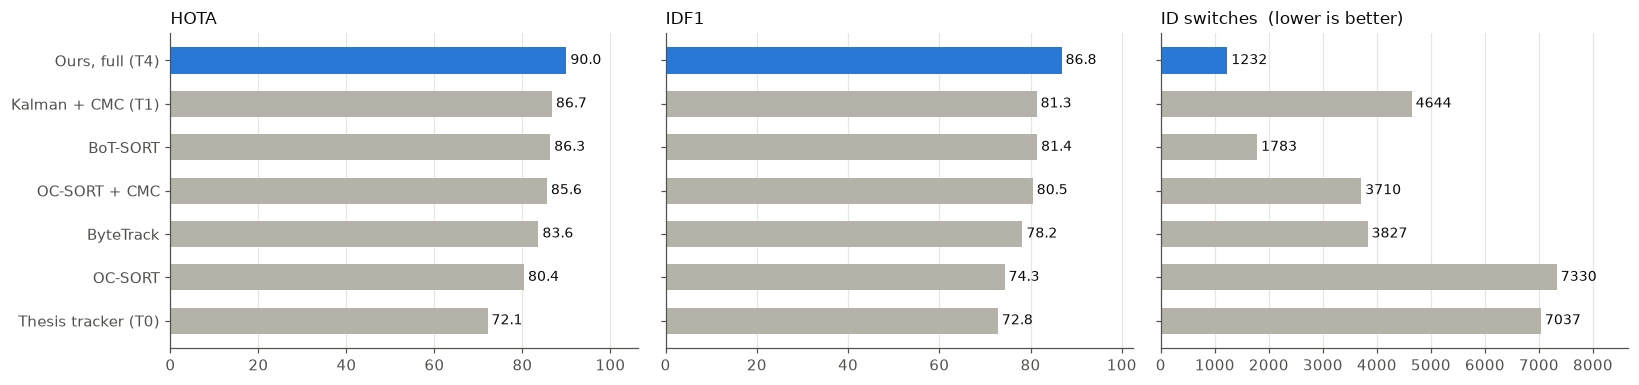

,HOTA,DetA,AssA,IDF1,MOTA,IDSW
tracker,,,,,,
Thesis tracker (T0),72.07,87.25,59.59,72.83,95.43,7037
ByteTrack,83.63,98.53,70.98,78.20,98.26,3827
OC-SORT,80.37,98.46,65.60,74.30,97.37,7330
OC-SORT + CMC,85.56,99.10,73.88,80.48,98.62,3710
BoT-SORT,86.31,98.85,75.36,81.43,98.72,1783
Kalman + CMC (T1),86.70,99.80,75.32,81.33,99.12,4644
"Ours, full (T4)",89.99,99.79,81.15,86.80,99.77,1232


In [2]:
V = ["T0", "X-bytetrack", "X-ocsort", "X-ocsort-cmc", "X-botsort", "T1", "T4"]
orc = viz.tracking_table("test", "oracle", V)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
bars(axs[0], orc, "HOTA", "HOTA"); bars(axs[1], orc, "IDF1", "IDF1"); bars(axs[2], orc, "IDSW", "ID switches", lower_better=True, fmt="{:.0f}")
for a in axs[1:]: a.set_yticklabels([])
plt.tight_layout(); plt.show()
orc.drop(columns="key")

**Is the gain real?** Paired test over the 49 sequences: mean per-sequence difference, 95% bootstrap CI,
Wilcoxon signed-rank p, and on how many sequences ours wins / ties / loses.

In [3]:
sig = viz.significance_table("test", "oracle")
sig.loc[[i for i in sig.index if i[1] in ("HOTA", "IDSW")]] if sig is not None else "significance not computed yet"

mean_diff  \
comparison                                    metric              
Ours, full (T4) vs Kalman + CMC (T1)          HOTA         3.35   
                                              IDSW       -69.63   
Ours, full (T4) vs Thesis tracker, bugs fixed HOTA        17.43   
                                              IDSW      -161.35   
Ours, full (T4) vs ByteTrack                  HOTA         6.96   
                                              IDSW       -52.96   
Ours, full (T4) vs OC-SORT                    HOTA        10.60   
                                              IDSW      -124.45   
Ours, full (T4) vs OC-SORT + CMC              HOTA         4.73   
                                              IDSW       -50.57   
Ours, full (T4) vs BoT-SORT                   HOTA         3.83   
                                              IDSW       -11.24   

                                                                    ci95  \
comparison                                    metric                       
Ours, full (T4) vs Kalman + CMC (T1)          HOTA          [2.46, 4.33]   
                                              IDSW      [-89.63, -52.37]   
Ours, full (T4) vs Thesis tracker, bugs fixed HOTA        [15.83, 19.15]   
                                              IDSW    [-214.76, -113.57]   
Ours, full (T4) vs ByteTrack                  HOTA          [5.42, 8.62]   
                                              IDSW      [-74.61, -34.29]   
Ours, full (T4) vs OC-SORT                    HOTA         [8.78, 12.48]   
                                              IDSW     [-167.02, -87.12]   
Ours, full (T4) vs OC-SORT + CMC              HOTA          [3.63, 5.99]   
                                              IDSW      [-68.43, -34.51]   
Ours, full (T4) vs BoT-SORT                   HOTA          [2.82, 4.95]   
                                              IDSW       [-18.00, -4.84]   

                                                     wilcoxon_p  \
comparison                                    metric              
Ours, full (T4) vs Kalman + CMC (T1)          HOTA      8.2e-09   
                                              IDSW      1.6e-09   
Ours, full (T4) vs Thesis tracker, bugs fixed HOTA      3.6e-15   
                                              IDSW      1.2e-09   
Ours, full (T4) vs ByteTrack                  HOTA      8.9e-14   
                                              IDSW      5.4e-09   
Ours, full (T4) vs OC-SORT                    HOTA      1.1e-14   
                                              IDSW      1.7e-09   
Ours, full (T4) vs OC-SORT + CMC              HOTA      2.5e-13   
                                              IDSW      1.2e-08   
Ours, full (T4) vs BoT-SORT                   HOTA      4.9e-13   
                                              IDSW      2.6e-05   

                                                     wins_ties_losses  
comparison                                    metric                   
Ours, full (T4) vs Kalman + CMC (T1)          HOTA             45/1/3  
                                              IDSW             48/1/0  
Ours, full (T4) vs Thesis tracker, bugs fixed HOTA             49/0/0  
                                              IDSW             48/0/1  
Ours, full (T4) vs ByteTrack                  HOTA             47/0/2  
                                              IDSW             45/0/4  
Ours, full (T4) vs OC-SORT                    HOTA             48/0/1  
                                              IDSW             47/1/1  
Ours, full (T4) vs OC-SORT + CMC              HOTA             47/0/2  
                                              IDSW             45/1/3  
Ours, full (T4) vs BoT-SORT                   HOTA             46/0/3  
                                              IDSW            38/1/10

### 1b. With a real detector (YOLO26-m, fine-tuned on SoccerNet-Tracking train)
The realistic setting. **Fair protocol:** every tracker's confidence thresholds were tuned on the same 15 held-out
sequences (the detector's validation sequences — never the test set), then run once on the 49 test sequences.
Ours additionally got *score-aware association* (confident detections drive matching and new tracks; weak ones
may only extend existing tracks) — without it, our advantage with real boxes was small.

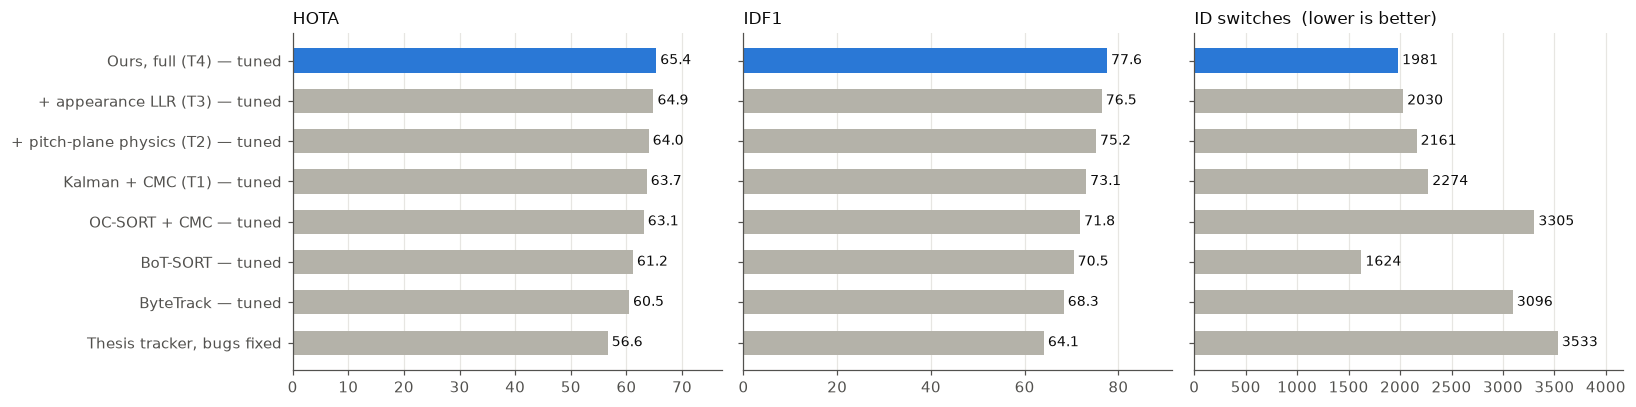

,HOTA,DetA,AssA,IDF1,MOTA,IDSW
tracker,,,,,,
"Thesis tracker, bugs fixed",56.63,70.67,45.52,64.11,86.76,3533
ByteTrack — tuned,60.47,73.23,50.05,68.34,88.96,3096
OC-SORT + CMC — tuned,63.12,74.18,53.82,71.84,90.16,3305
BoT-SORT — tuned,61.17,71.72,52.26,70.45,87.26,1624
Kalman + CMC (T1) — tuned,63.65,73.64,55.12,73.12,89.39,2274
+ pitch-plane physics (T2) — tuned,63.99,73.46,55.85,75.22,89.46,2161
+ appearance LLR (T3) — tuned,64.86,73.61,57.25,76.45,89.52,2030
"Ours, full (T4) — tuned",65.35,73.60,58.12,77.57,89.53,1981


In [4]:
V2 = ["T0-fixed", "X-bytetrack-tuned", "X-ocsort-cmc-tuned", "X-botsort-tuned", "T1-tuned", "T2-tuned", "T3-tuned", "T4-tuned"]
yol = viz.tracking_table("test", "yolo26m_snmot", V2)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (c, t, lb, f) in zip(axs, [("HOTA", "HOTA", False, "{:.1f}"), ("IDF1", "IDF1", False, "{:.1f}"), ("IDSW", "ID switches", True, "{:.0f}")]):
    bars(ax, yol, c, t, ours_keys=("T4-tuned",), lower_better=lb, fmt=f)
for a in axs[1:]: a.set_yticklabels([])
plt.tight_layout(); plt.show()
yol.drop(columns="key")

In [5]:
sig2 = viz.significance_table("test", "yolo26m_snmot", ours="T4-tuned")
sig2.loc[[i for i in sig2.index if i[1] in ("HOTA", "IDSW")]] if sig2 is not None else "significance not computed yet"

mean_diff  \
comparison                                                    metric              
Ours, full (T4) — tuned vs Kalman + CMC (T1) — tuned          HOTA         1.62   
                                                              IDSW        -5.98   
Ours, full (T4) — tuned vs + pitch-plane physics (T2) — tuned HOTA         1.20   
                                                              IDSW        -3.67   
Ours, full (T4) — tuned vs + appearance LLR (T3) — tuned      HOTA         0.50   
                                                              IDSW        -1.00   
Ours, full (T4) — tuned vs ByteTrack — tuned                  HOTA         5.28   
                                                              IDSW       -22.76   
Ours, full (T4) — tuned vs OC-SORT + CMC — tuned              HOTA         2.21   
                                                              IDSW       -27.02   
Ours, full (T4) — tuned vs BoT-SORT — tuned                   HOTA         4.45   
                                                              IDSW         7.29   

                                                                                  ci95  \
comparison                                                    metric                     
Ours, full (T4) — tuned vs Kalman + CMC (T1) — tuned          HOTA        [0.83, 2.40]   
                                                              IDSW      [-9.04, -3.00]   
Ours, full (T4) — tuned vs + pitch-plane physics (T2) — tuned HOTA        [0.52, 1.89]   
                                                              IDSW      [-5.71, -1.71]   
Ours, full (T4) — tuned vs + appearance LLR (T3) — tuned      HOTA        [0.23, 0.80]   
                                                              IDSW      [-1.33, -0.69]   
Ours, full (T4) — tuned vs ByteTrack — tuned                  HOTA        [4.00, 6.66]   
                                                              IDSW    [-34.08, -13.47]   
Ours, full (T4) — tuned vs OC-SORT + CMC — tuned              HOTA        [1.34, 3.13]   
                                                              IDSW    [-31.80, -22.65]   
Ours, full (T4) — tuned vs BoT-SORT — tuned                   HOTA        [3.36, 5.58]   
                                                              IDSW       [2.88, 12.04]   

                                                                     wilcoxon_p  \
comparison                                                    metric              
Ours, full (T4) — tuned vs Kalman + CMC (T1) — tuned          HOTA      3.0e-04   
                                                              IDSW      1.3e-04   
Ours, full (T4) — tuned vs + pitch-plane physics (T2) — tuned HOTA      4.9e-03   
                                                              IDSW      7.9e-04   
Ours, full (T4) — tuned vs + appearance LLR (T3) — tuned      HOTA      1.8e-03   
                                                              IDSW      7.8e-07   
Ours, full (T4) — tuned vs ByteTrack — tuned                  HOTA      2.7e-11   
                                                              IDSW      1.7e-07   
Ours, full (T4) — tuned vs OC-SORT + CMC — tuned              HOTA      3.4e-05   
                                                              IDSW      1.1e-09   
Ours, full (T4) — tuned vs BoT-SORT — tuned                   HOTA      2.6e-10   
                                                              IDSW      8.4e-03   

                                                                     wins_ties_losses  
comparison                                                    metric                   
Ours, full (T4) — tuned vs Kalman + CMC (T1) — tuned          HOTA            36/0/13  
                                                              IDSW             37/3/9  
Ours, full (T4) — tuned vs + pitch-plane physics (T2) — tuned HOTA            31/1/17  
                                           

What tuning changed (test set) — untuned = thresholds as designed for perfect boxes / library defaults:

In [6]:
pairs = [("T1", "T1-tuned"), ("T4", "T4-tuned"), ("X-bytetrack", "X-bytetrack-tuned"), ("X-ocsort-cmc", "X-ocsort-cmc-tuned"), ("X-botsort", "X-botsort-tuned")]
allv = viz.tracking_table("test", "yolo26m_snmot", [v for p in pairs for v in p])
pd.DataFrame([{"tracker": viz.nice(a), "HOTA untuned": allv.loc[viz.nice(a), "HOTA"], "HOTA tuned": allv.loc[viz.nice(b), "HOTA"],
               "IDSW untuned": allv.loc[viz.nice(a), "IDSW"], "IDSW tuned": allv.loc[viz.nice(b), "IDSW"]}
              for a, b in pairs if viz.nice(a) in allv.index and viz.nice(b) in allv.index]).set_index("tracker")

,HOTA untuned,HOTA tuned,IDSW untuned,IDSW tuned
tracker,,,,
Kalman + CMC (T1),62.05,63.65,3197,2274
"Ours, full (T4)",62.65,65.35,3832,1981
ByteTrack,57.03,60.47,2261,3096
OC-SORT + CMC,55.80,63.12,2371,3305
BoT-SORT,57.41,61.17,1832,1624


### 1c. What an identity switch looks like
Moments (perfect boxes) where **BoT-SORT changes a player's ID** within ≤3 frames while **ours keeps it**.
Colour and number = track identity. Crops are centred on the player concerned (white outline).

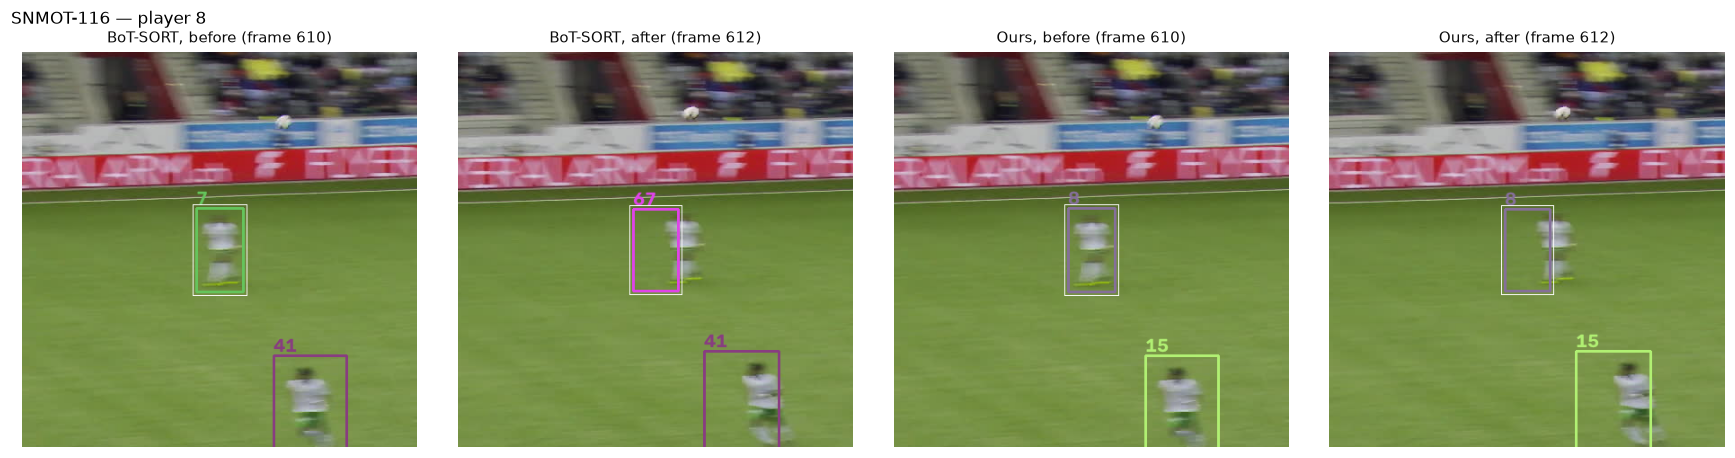

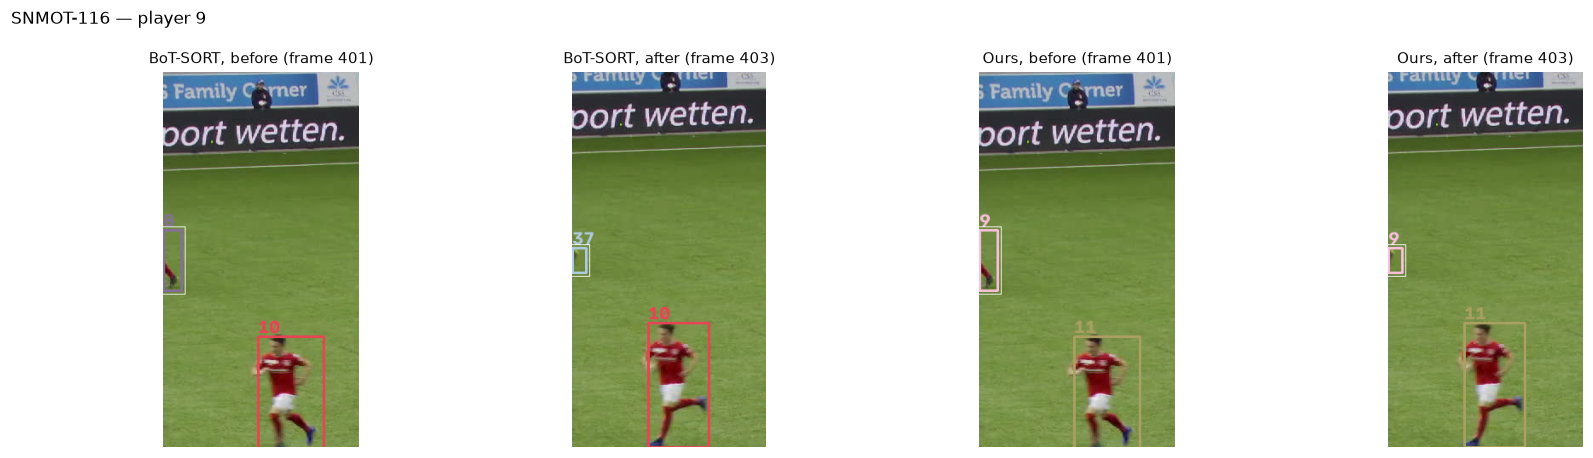

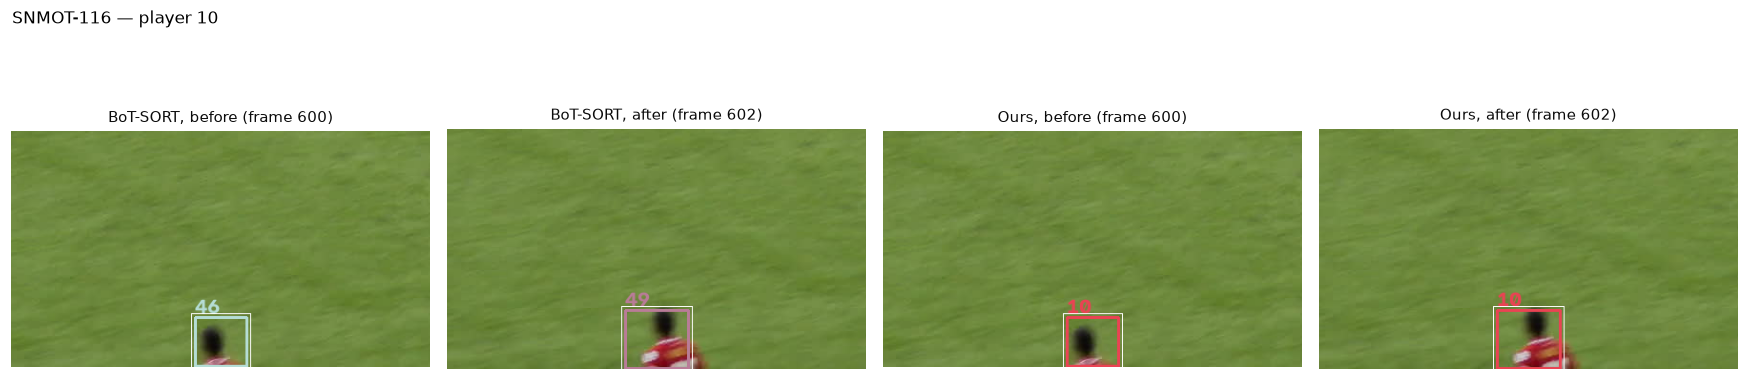

In [7]:
seqs = sorted(p.name for p in (ROOT / "outputs/tracking/test/oracle/T4").glob("*.txt"))
ex = viz.find_switch_examples("test", "oracle", "T4", "X-botsort", [Path(s).stem for s in seqs][:12], max_n=3)
for e in ex:
    fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
    for k, (v, f, lab) in enumerate([("X-botsort", e["f0"], "BoT-SORT, before"), ("X-botsort", e["f1"], "BoT-SORT, after"),
                                     ("T4", e["f0"], "Ours, before"), ("T4", e["f1"], "Ours, after")]):
        axs[k].imshow(viz.draw_tracks("test", "oracle", v, e["seq"], f, focus_gt=e["gt_id"]))
        axs[k].set_title(f"{lab} (frame {f})", fontsize=10, color=INK); axs[k].axis("off")
    fig.suptitle(f"{e['seq']} — player {e['gt_id']}", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()
if not ex: print("no example found in the first sequences")

## 2. Camera calibration — PitchGeo (predicts line equations + ellipses, then solves the camera)

| | what changed |
|---|---|
| v1 | Laplace (probabilistic) loss with a hard σ clamp; not symmetry-aware |
| v2 | σ bounded smoothly (tanh) + **mirror-invariant** loss (the pitch looks the same rotated 180°) |
| deterministic | v2 code with a Huber loss instead of the probabilistic one (ablation) |

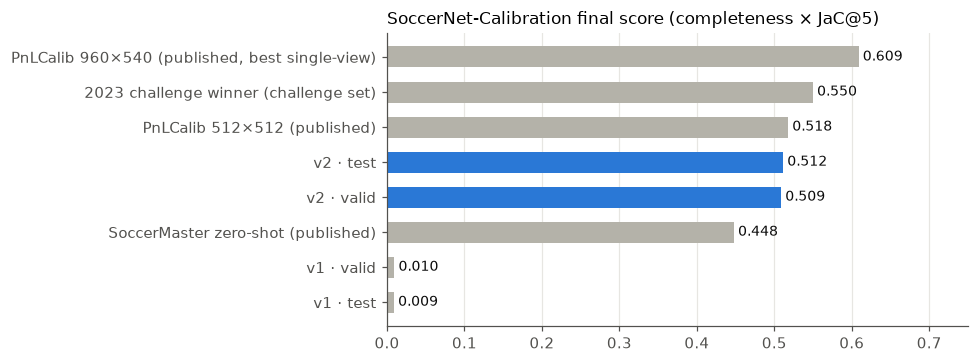

Published numbers: sota2.com leaderboard / SoccerNet 2023 results. Ours: our re-implementation of the metric (not yet cross-checked with the official script).


,completeness,JaC@5,JaC@10,JaC@20,final_score
model,,,,,
v1 · valid,0.82,0.01,0.04,0.11,9.65e-03
v1 · test,0.79,0.01,0.04,0.11,9.17e-03
v2 · valid,0.98,0.52,0.67,0.71,5.09e-01
v2 · test,0.98,0.52,0.66,0.70,5.12e-01


In [8]:
rows = []
for tag, name in [("K3_prob_valid", "v1 · valid"), ("K3_prob_test", "v1 · test"), ("K3v2_prob_valid", "v2 · valid"), ("K3v2_prob_test", "v2 · test")]:
    p = ROOT / f"outputs/pitchgeo/eval/{tag}.json"
    if p.exists():
        d = json.loads(p.read_text()); rows.append(dict(model=name, completeness=d["completeness"], **{k: d[k] for k in ("JaC@5", "JaC@10", "JaC@20")}, final_score=d["final_score"]))
cal = pd.DataFrame(rows).set_index("model")
pub = pd.DataFrame([("PnLCalib 960×540 (published, best single-view)", 0.609), ("PnLCalib 512×512 (published)", 0.518),
                    ("SoccerMaster zero-shot (published)", 0.448), ("2023 challenge winner (challenge set)", 0.55)],
                   columns=["method", "final score"]).set_index("method")
fig, ax = plt.subplots(figsize=(9, 3.4))
allr = pd.concat([cal["final_score"].rename("final score").to_frame(), pub])
allr = allr.sort_values("final score")
ax.barh(allr.index, allr["final score"], color=[OURS if i.startswith("v2") else BASE for i in allr.index], height=0.6)
for y, v in enumerate(allr["final score"]): ax.text(v, y, f" {v:.3f}", va="center", fontsize=9, color=INK)
ax.set_title("SoccerNet-Calibration final score (completeness × JaC@5)", loc="left", fontsize=11); ax.grid(axis="y", visible=False); ax.set_xlim(0, 0.75)
plt.tight_layout(); plt.show()
print("Published numbers: sota2.com leaderboard / SoccerNet 2023 results. Ours: our re-implementation of the metric (not yet cross-checked with the official script).")
cal

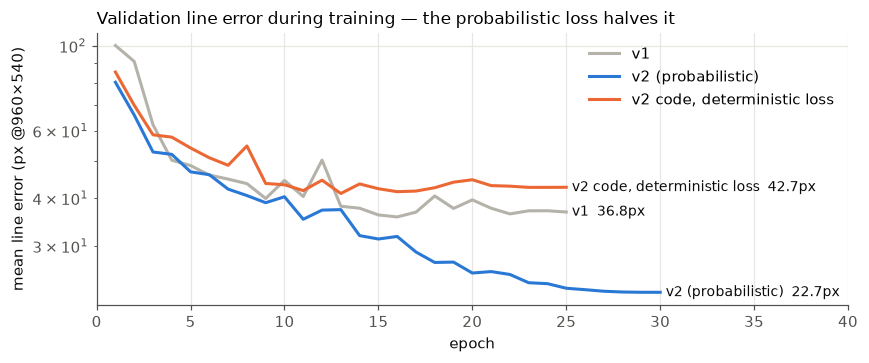

In [9]:
tr = {}
for run in ("kaggle_run1", "kaggle_v2", "kaggle_det"):
    p = ROOT / f"outputs/pitchgeo/{run}/run/log.jsonl"
    if p.exists(): tr[run] = [json.loads(l)["valid"]["line_px540"] for l in open(p)]
fig, ax = plt.subplots(figsize=(8, 3.4))
lab = {"kaggle_run1": "v1", "kaggle_v2": "v2 (probabilistic)", "kaggle_det": "v2 code, deterministic loss"}
col = {"kaggle_run1": BASE, "kaggle_v2": OURS, "kaggle_det": "#eb6834"}
for k, v in tr.items():
    ax.plot(range(1, len(v) + 1), v, color=col[k], lw=2, label=lab[k]); ax.text(len(v) + 0.3, v[-1], f"{lab[k]}  {v[-1]:.1f}px", va="center", fontsize=9, color=INK)
ax.set_xlabel("epoch"); ax.set_ylabel("mean line error (px @960×540)"); ax.set_yscale("log")
ax.set_title("Validation line error during training — the probabilistic loss halves it", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right"); ax.set_xlim(0, 40); plt.tight_layout(); plt.show()

**On real frames.** White dots = annotated pitch markings; magenta = the whole pitch model projected through the
camera solved from the network's predictions. Accuracy = share of annotated markings within 5 px.
Random sample of validation images (fixed seed), v1 left, v2 right.

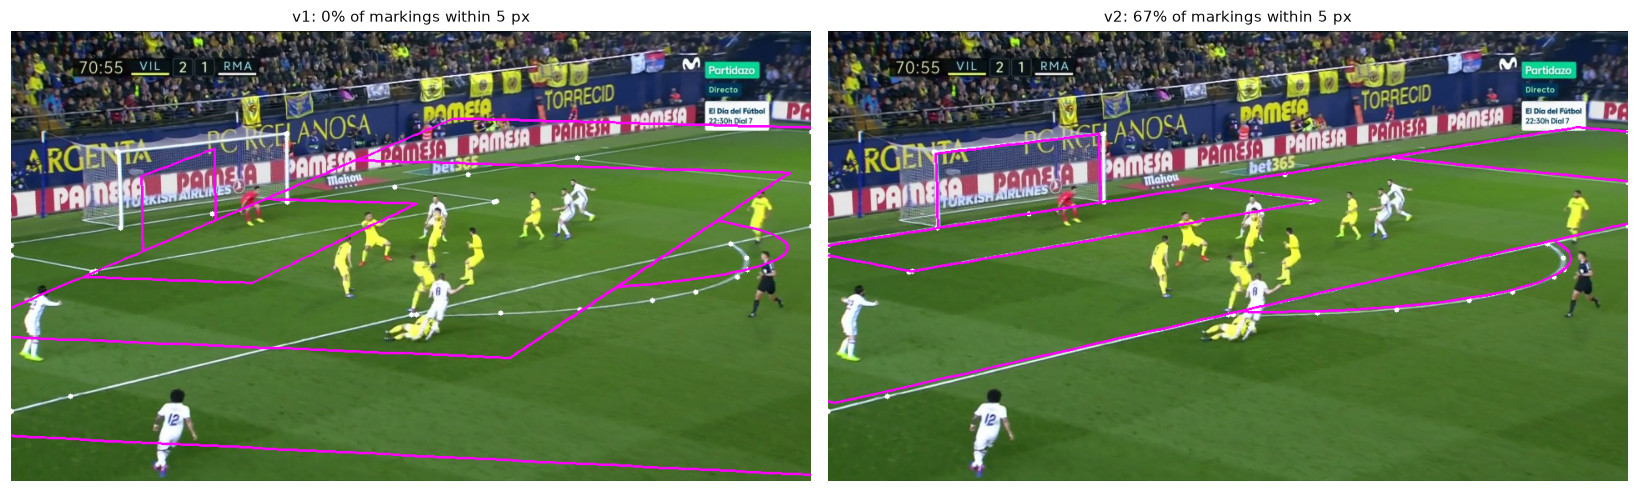

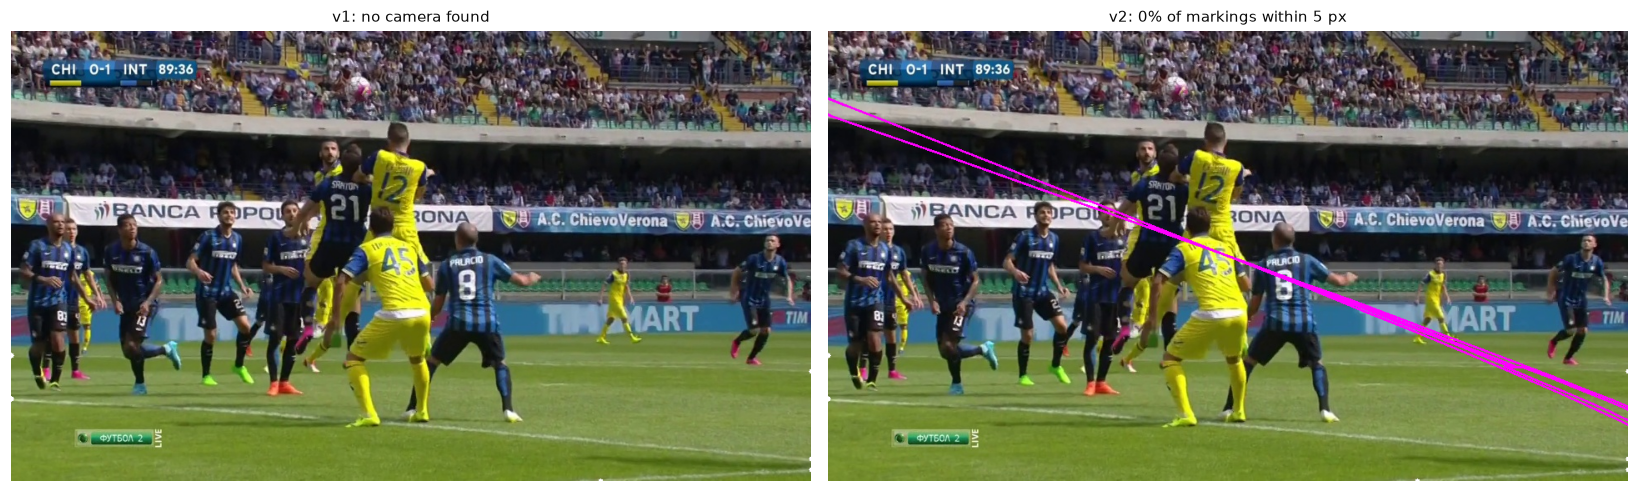

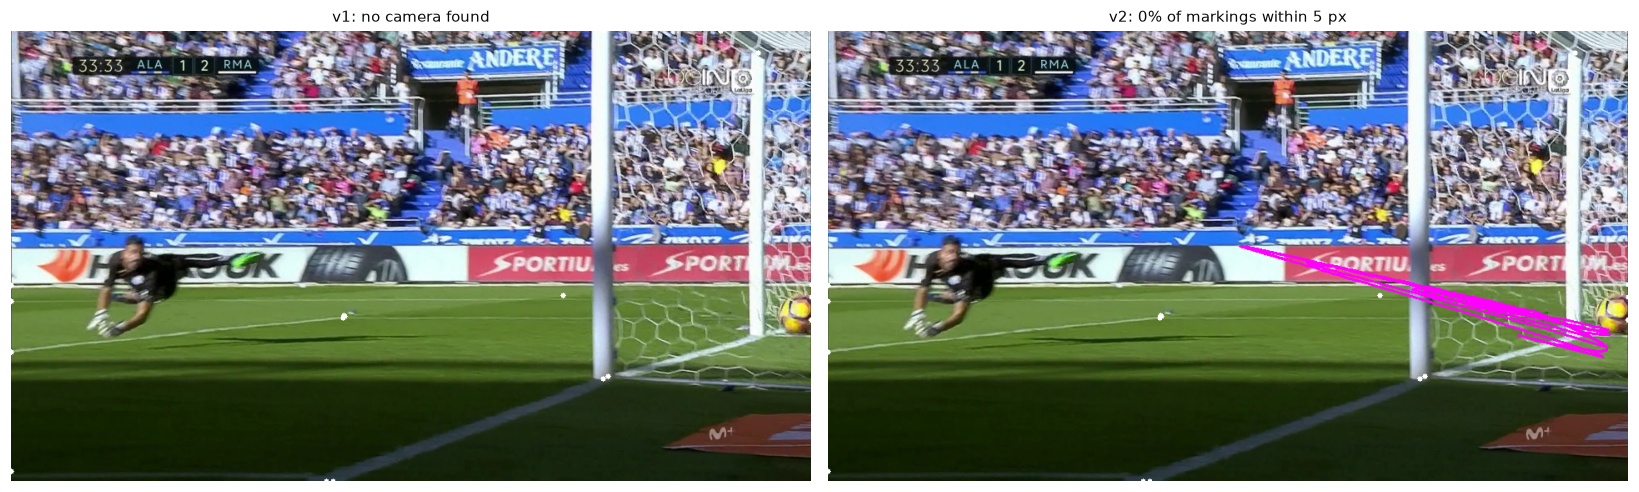

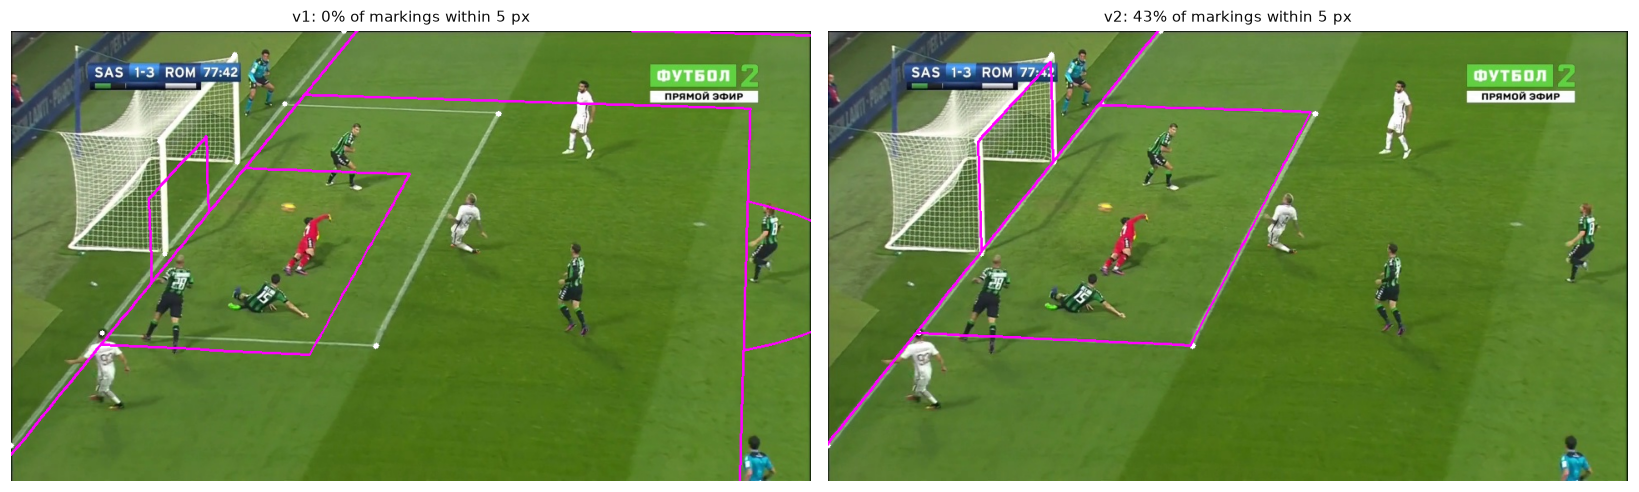

In [10]:
Z = Path.home() / "soccerNet/hf/calib2023/valid.zip"
n_img = len(np.load(ROOT / "outputs/pitchgeo/eval/K3v2_prob_valid_raw.npz")["names"])
idx = np.random.default_rng(7).choice(n_img, 4, replace=False)
for i in idx:
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
    for ax, (tag, name) in zip(axs, [("K3_prob_valid", "v1"), ("K3v2_prob_valid", "v2")]):
        img, acc = viz.calib_overlay(tag, Z, int(i))
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{name}: " + ("no camera found" if acc is None else f"{100 * acc:.0f}% of markings within 5 px"), fontsize=10, color=INK)
    plt.tight_layout(); plt.show()

## 3. Ball tracking
**Bug found and fixed:** the physics tracker (B2/B3: rolling / in-air / possession modes) needed a full 3-D camera,
which can be recovered in only ~8% of frames, so it output almost nothing. Fix: fall back to the pitch homography
(exact for a ball on the ground). Ball tracking is the next big work item (see the end).

In [11]:
b = json.loads((ROOT / "outputs/ball/train/yolov8m_repo/summary.json").read_text())
nofb = ROOT / "outputs/ball/train/yolov8m_repo/summary-nofb.json"
rows = {"B0 best detection": b["B0"], "B1 image Kalman": b["B1"], "B2 physics IMM (fixed)": b["B2"], "B3 + possession (fixed)": b["B3"]}
for f in (ROOT / "outputs/ball/train/yolov8m_repo").glob("summary*nofb*.json"):
    rows["B2 physics IMM (before fix)"] = json.loads(f.read_text()).get("B2-nofb", json.loads(f.read_text()).get("B2"))
bt = pd.DataFrame(rows).T[["HOTA", "recall@10", "prec@10", "out_frames", "gt_frames"]]
bt

,HOTA,recall@10,prec@10,out_frames,gt_frames
B0 best detection,32.80,53.84,90.04,6074.0,10158.0
B1 image Kalman,27.38,59.58,65.32,9265.0,10158.0
B2 physics IMM (fixed),27.81,54.89,71.25,7826.0,10158.0
B3 + possession (fixed),28.14,55.18,71.93,7792.0,10158.0
B2 physics IMM (before fix),3.33,3.18,51.52,627.0,10158.0


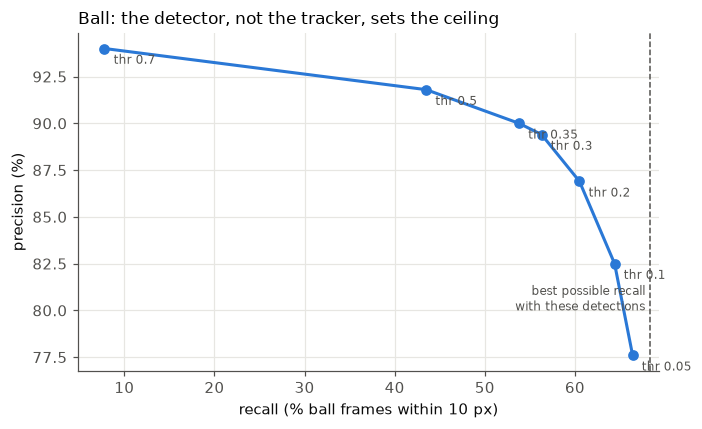

{'gt_ball_frames': 10158,
 'oracle_selection_recall@r': {'0.05': 68.3, '0.1': 65.4, '0.2': 61.1},
 'B0@0.35 + interp gaps<=L (recall, precision)': {'5': [58.7, 87.9],
  '10': [61.2, 85.7],
  '25': [63.9, 80.3],
  '50': [65.4, 74.4]},
 'B0@0.35 + CMC interp gaps<=L (recall, precision)': {'5': [58.7, 87.9],
  '10': [61.2, 85.7],
  '25': [63.8, 80.2],
  '50': [65.0, 74.0]},
 'miss_gap_frames(p50,p75,p90,max)': [2, 5, 14, 223],
 'frac_missed_frames_in_gaps<=10': 0.339,
 'gt_ball_size_px(p10,p50,p90)': [8.0, 15.0, 21.5],
 'candidates_per_gt_frame(mean, frac0)': [1.41, 0.184],
 'score_of_correct_candidate(p10,p50,p90)': [0.09, 0.53, 0.7]}

In [12]:
ce = json.loads((ROOT / "outputs/diag/ball_ceiling_train_yolov8m_repo.json").read_text())
sw = ce["B0_sweep(thr: recall, precision)"]
fig, ax = plt.subplots(figsize=(6.5, 4))
r = [v[0] for v in sw.values()]; p = [v[1] for v in sw.values()]
ax.plot(r, p, color=OURS, lw=2, marker="o", ms=6)
for t, (rr, pp) in sw.items(): ax.annotate(f"thr {t}", (rr, pp), textcoords="offset points", xytext=(6, -10), fontsize=8, color=MUTED)
ax.axvline(ce["oracle_selection_recall@r"]["0.05"], color=MUTED, ls="--", lw=1)
ax.text(ce["oracle_selection_recall@r"]["0.05"] - 0.5, 80, "best possible recall\nwith these detections", ha="right", fontsize=8, color=MUTED)
ax.set_xlabel("recall (% ball frames within 10 px)"); ax.set_ylabel("precision (%)")
ax.set_title("Ball: the detector, not the tracker, sets the ceiling", loc="left", fontsize=11)
plt.tight_layout(); plt.show()
{k: v for k, v in ce.items() if "sweep" not in k}

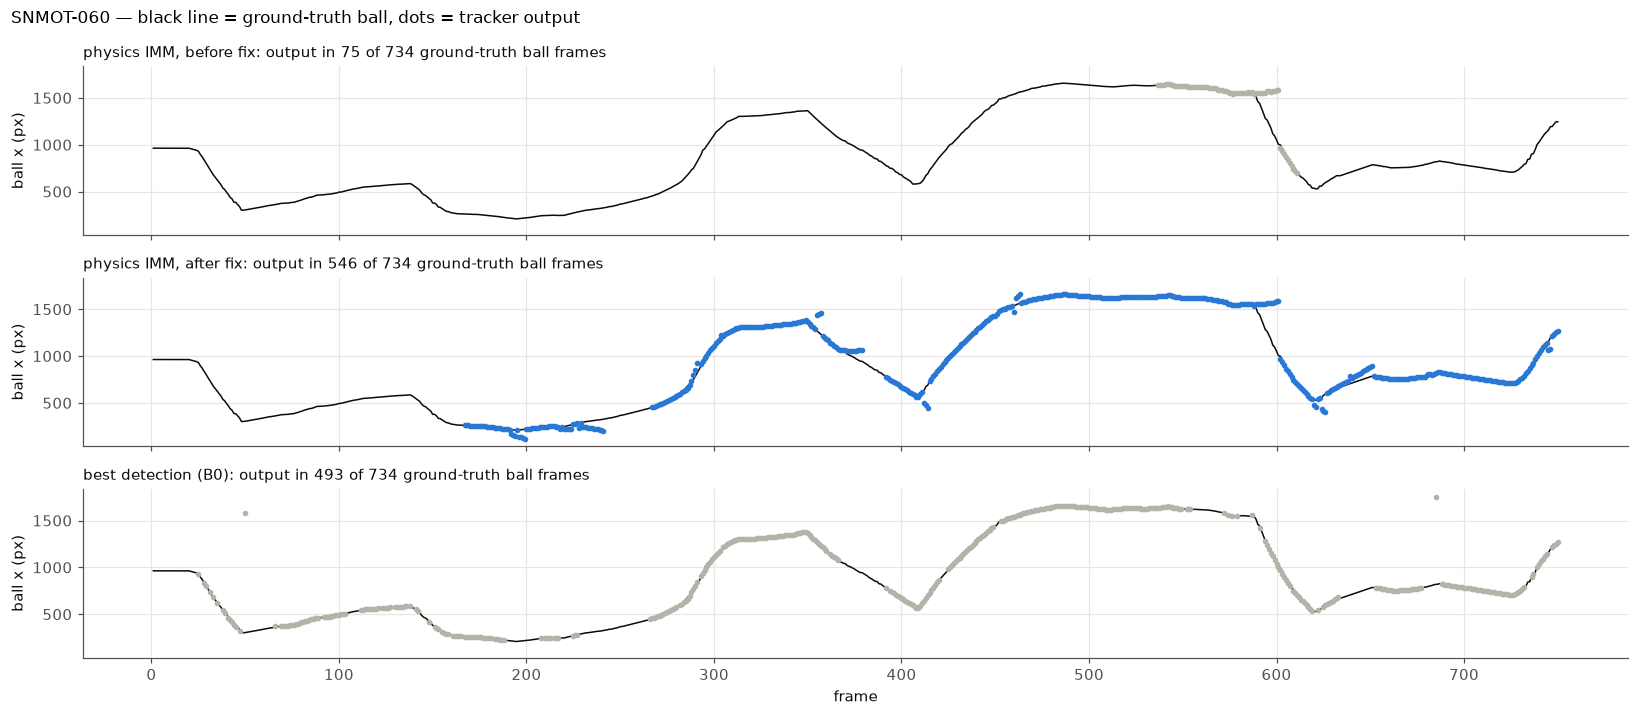

In [13]:
s = sorted(p.stem for p in (ROOT / "outputs/ball/train/yolov8m_repo/B0").glob("*.txt"))[0]
g = viz.ball_gt_series("train", s)
runs = [("B2-nofb", "physics IMM, before fix"), ("B2", "physics IMM, after fix"), ("B0", "best detection (B0)")]
fig, axs = plt.subplots(len(runs), 1, figsize=(15, 6.6), sharex=True, sharey=True)
for ax, (v, lab) in zip(axs, runs):
    q = viz.ball_series("train", "yolov8m_repo", v, s)
    ax.plot(g.index, g.values, color=INK, lw=1)
    ax.scatter(q.index, q.values, s=7, color=OURS if v == "B2" else BASE, zorder=3)
    ax.set_title(f"{lab}: output in {len(q)} of {len(g)} ground-truth ball frames", loc="left", fontsize=10, color=INK)
    ax.set_ylabel("ball x (px)")
axs[-1].set_xlabel("frame")
fig.suptitle(f"{s} — black line = ground-truth ball, dots = tracker output", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

## 4. Commentary — small local model (Qwen3.5) fine-tuned with QLoRA
Input: a text game state (score, cards, recent events). **Caveat:** events come from ground-truth labels here;
a live system must detect them first.

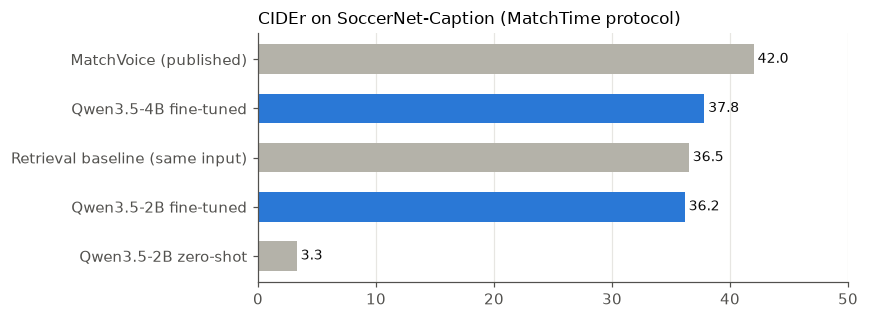

,BLEU-4,METEOR,ROUGE-L,CIDEr,sec_per_caption
Qwen3.5-2B zero-shot,0.69,15.01,12.54,3.27,0.30
Qwen3.5-2B fine-tuned,8.73,25.06,27.35,36.15,0.34
Qwen3.5-4B fine-tuned,8.33,25.89,27.10,37.81,0.63


In [14]:
rows = {}
for name, p in [("Qwen3.5-2B zero-shot", "outputs/commentary/g1_2b_test_metrics.json"), ("Qwen3.5-2B fine-tuned", "outputs/commentary/g2_2b_test_metrics.json"),
                ("Qwen3.5-4B fine-tuned", "outputs/commentary/kaggle_g2_4b/g2_4b_test_metrics.json")]:
    if (ROOT / p).exists(): rows[name] = json.loads((ROOT / p).read_text())
cm = pd.DataFrame(rows).T[["BLEU-4", "METEOR", "ROUGE-L", "CIDEr", "sec_per_caption"]]
ref = pd.DataFrame({"CIDEr": {"Retrieval baseline (same input)": 36.5, "MatchVoice (published)": 42.0}})
allc = pd.concat([cm[["CIDEr"]], ref]).sort_values("CIDEr")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(allc.index, allc["CIDEr"], color=[OURS if "fine-tuned" in i else BASE for i in allc.index], height=0.6)
for y, v in enumerate(allc["CIDEr"]): ax.text(v, y, f" {v:.1f}", va="center", fontsize=9, color=INK)
ax.set_title("CIDEr on SoccerNet-Caption (MatchTime protocol)", loc="left", fontsize=11); ax.grid(axis="y", visible=False); ax.set_xlim(0, 50)
plt.tight_layout(); plt.show()
cm

In [15]:
viz.caption_samples({"zero-shot 2B": ROOT / "outputs/commentary/g1_2b_test.jsonl", "fine-tuned 2B": ROOT / "outputs/commentary/g2_2b_test.jsonl",
                     "fine-tuned 4B": ROOT / "outputs/commentary/kaggle_g2_4b/g2_4b_test.jsonl"}, n=5, seed=3)

,"game state (input, truncated)",reference,zero-shot 2B,fine-tuned 2B,fine-tuned 4B
0,"Half 2, 20:23. Score [TEAM_HOME] 0-2 [TEAM_AWAY]. Cards [TEAM_HOME] 2, [TEAM_AWAY] 1. Actions around now: -34s Ball out of play; -18s Clearance ([TEAM_HOME]); +…",An attempted cross from [PLAYER] ([TEAM]) is cleared.,The [TEAM_AWAY] keeper makes a brilliant save to deny a shot from [PLAYER] who is currently under pressure.,"[PLAYER] ([TEAM]) sends a cross into the box, but the opposition's defence clears the ball to safety.","[PLAYER] ([TEAM]) sends a cross into the box, but the opposition's defence clears the ball to safety."
1,"Half 2, 18:22. Score [TEAM_HOME] 0-2 [TEAM_AWAY]. Cards [TEAM_HOME] 3, [TEAM_AWAY] 3. Actions around now: -42s Clearance ([TEAM_HOME]); -29s Ball out of play; -…",Nothing comes of the resulting corner from [PLAYER] ([TEAM]). The defence is alert and manages to cut it out.,The [TEAM_AWAY] has taken the lead with a well-placed shot from +3s that cleared the [TEAM_HOME] defense.,[PLAYER] ([TEAM]) takes the corner but fails to find any of his teammates. The ball is easily cleared out of danger.,[PLAYER] ([TEAM]) takes the corner but fails to find any of his teammates. The ball is easily cleared out of danger.
2,"Half 2, 21:06. Score [TEAM_HOME] 1-2 [TEAM_AWAY]. Cards [TEAM_HOME] 2, [TEAM_AWAY] 3. Actions around now: -1s Shots off target ([TEAM_AWAY]); -1s Direct free-ki…",What a chance to score from the free kick by [PLAYER] ([TEAM]). He unleashed a sharp shot that sailed just wide of the right post.,The [TEAM_AWAY] has been denied a clear chance with a direct free-kick that was cleared by the [TEAM_HOME] defense.,"[PLAYER] ([TEAM]) takes the free kick from the edge of the box, but [PLAYER] reacts well to keep the ball out.","[PLAYER] ([TEAM]) takes the free kick from the edge of the box, but the goalkeeper perfectly sets up the defensive wall and his effort is thwarted."
3,"Half 1, 32:12. Score [TEAM_HOME] 0-0 [TEAM_AWAY]. Cards [TEAM_HOME] 0, [TEAM_AWAY] 0. Actions around now: -1s Shots on target ([TEAM_HOME]); +1s Ball out of pla…","[PLAYER] ([TEAM]) bursts into the box and pulls the trigger, but he can't beat the goalkeeper. He directed his shot towards the right post, but one of the defenders reacted brilliantly to block it...",[TEAM_HOME] has taken a shot from -1s which is saved by [REFEREE] and the ball goes out of play.,"[PLAYER] ([TEAM]) receives a precise pass on the edge of the box and has an effort on goal. Unfortunately for him, his strike flies narrowly wide of the left post.",[PLAYER] ([TEAM]) receives a precise pass and is given time inside the box to send a promising strike towards the middle of the goal. [PLAYER] guesses his intention and denies him with a fine save.
4,"Half 2, 27:53. Score [TEAM_HOME] 1-2 [TEAM_AWAY]. Cards [TEAM_HOME] 2, [TEAM_AWAY] 2. Actions around now: -37s Foul ([TEAM_AWAY]); -29s Yellow card ([TEAM_AWAY]…",[PLAYER] ([TEAM]) whips a long ball in from the free kick which is intercepted by [PLAYER].,"The [TEAM_AWAY] player is sent off for a foul in the 37th minute, leaving the [TEAM_HOME] side with two points and a direct free-kick in the 2nd minute.","[PLAYER] ([TEAM]) is awarded a yellow card for his tackle. He doesn't seem to agree with the decision, but [REFEREE] ignores the protests.",[PLAYER] ([TEAM]) is booked after bringing down an opponent. [REFEREE] had an easy-decision to make.


## Not shown yet
* Tracking caveat: the published trackers run without a learned ReID model (as does ours); BoT-SORT with ReID is a
  separate comparison still to do.
* **End-to-end pipeline** (video → detector → tracker → calibration → events → commentary): components are
  benchmarked separately; integration into `pipeline/` is pending.
* **Ball: detection + 3-D** — next work item (tracking-guided re-detection, per-video online learning,
  ballistic 3-D from gravity + full camera from goal posts/crossbar/corner flags).
* Event spotting, jersey numbers, second dataset, official calibration scorer cross-check.